# Text Summarization: how hard is "the first three sentences" to beat?

**The question:** the legacy script summarises a Wikipedia page by counting how often each word appears, scoring every sentence by the sum of its words' counts and printing the top five. It looks sensible and it shows a summary, but it never asks whether the summary is *good*. *How do we measure a summary? How does the word-count method compare with the simplest baseline ever, "just take the first three sentences"? Does a graph method (TextRank) help? How much does an abstractive neural model (BART) add, and what does it invent? And how much better could any three-sentence summary be?* We test on **500 news articles with human-written bullet-point summaries** from CNN and the Daily Mail.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the articles
4. Hypotheses and why we chose each test
5. The four summarisers
6. H1: is the legacy word-count method better than the first three sentences?
7. H2: does a graph method help?
8. H3: how much does an abstractive model add, and how much is left?
9. H4: where do the best sentences live?
10. H5: does the abstractive model invent things?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab NLP/text-summarization/text_summarization.ipynb`, or *Run All* in any Jupyter. The articles (about 30 MB) and BART (about 1.6 GB) download themselves on the first run. It uses a GPU if present and takes about 20 minutes on one.

## 1. 💡 The simple analogy

Imagine summarising a **newspaper story** for a busy friend.

- **The lazy editor** reads out the first three sentences. News is written with the most important facts at the top, so this works surprisingly well.
- **The word-counting editor (the legacy method)** circles the words that occur most often and reads out the sentences that contain the most circled words. Long, repetitive sentences win, wherever they are.
- **The "who is connected to whom" editor (TextRank)** picks the sentences that are most similar to many other sentences, on the idea that central sentences carry the topic.
- **The writer (BART)** reads the whole story and writes new sentences in their own words. They are fluent and compact, but they may add a stadium name they once heard about.
- **A strict teacher** compares each summary with the bullet points a human wrote.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of articles (500), the number of sentences each extractive method returns (3) and BART's input limit (1,024 word-pieces) keeps the notebook reproducible and avoids "magic numbers".

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import heapq
import re
import time
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from huggingface_hub.utils import logging as hub_logging
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize
from rouge_score import rouge_scorer
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
datasets.disable_progress_bars()
for resource in ("punkt_tab", "stopwords"):
    nltk.download(resource, quiet=True)

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
MODEL_NAME = "facebook/bart-large-cnn"
SEED = 365
N_ARTICLES = 500
N_SENTENCES = 3  # every extractive method returns this many sentences
MAX_INPUT_TOKENS = 1024
BATCH = 4
N_BOOTSTRAP = 1_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the articles

*What:* the **CNN/DailyMail** test set (11,490 news stories), each with its **highlights**: the bullet points written by the journalists, which we use as the reference summary. We draw 500 articles at random, split each into sentences, and look at lengths and how much of the reference is copied from the article. *Why:* the reference defines "good", so we should know what it looks like.

> **Problems in the legacy script this replaces:** it scraped **one live Wikipedia page** (the film "The Avengers"), so nothing was reproducible; its output was a JSON file of five sentences with **no reference to compare with**; it returned the sentences in order of score, not in reading order; and it silently skipped any sentence of 30 words or more.

In [2]:
news = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test", cache_dir=str(DATA_DIR / "hf"))
sample = news.shuffle(seed=SEED).select(range(N_ARTICLES)).to_pandas()
sample["sentences"] = sample["article"].map(sent_tokenize)
sample["n_sentences"] = sample["sentences"].map(len)
sample["article_words"] = sample["article"].str.split().str.len()
sample["reference_words"] = sample["highlights"].str.split().str.len()
print(f"{len(news):,} test articles in CNN/DailyMail; {len(sample)} drawn at random")
print(
    "Article: median {:.0f} words ({:.0f} sentences), 90th percentile {:.0f} words".format(
        sample["article_words"].median(),
        sample["n_sentences"].median(),
        sample["article_words"].quantile(0.9),
    )
)
print(
    "Reference summary (the story's bullet 'highlights'): median {:.0f} words, "
    "{:.1f} bullets".format(
        sample["reference_words"].median(), sample["highlights"].str.count("\n").add(1).mean()
    )
)
dateline = sample["article"].str[:120].str.contains(r"\(CNN\)|\(.*\) --|By \. ").mean()
print(f"Articles that start with a dateline or '(CNN)': {dateline:.0%}")
overlap = np.mean(
    [
        len(set(h.lower().split()) & set(a.lower().split())) / len(set(h.lower().split()))
        for h, a in zip(sample["highlights"], sample["article"], strict=True)
    ]
)
print(f"Reference words that also appear in the article: {overlap:.0%}")
print("\nFirst reference summary:\n  " + sample["highlights"].iloc[0].replace("\n", "\n  "))

11,490 test articles in CNN/DailyMail; 500 drawn at random
Article: median 621 words (30 sentences), 90th percentile 1212 words
Reference summary (the story's bullet 'highlights'): median 50 words, 3.8 bullets
Articles that start with a dateline or '(CNN)': 10%
Reference words that also appear in the article: 81%

First reference summary:
  Fernando Torres hailed Steven Gerrard as the best he ever played with .
  The 31-year-old struck up a friendship with Gerrard while at Liverpool .
  Torres has never quite rekindled his top form since leaving Anfield .
  CLICK HERE for all the latest Liverpool news .


**How to read this:**

- **A typical article is long and a typical reference short:** the median article has **621 words (30 sentences)** and the median reference **50 words in 3.8 bullets**.
- **The reference is mostly extractive in vocabulary:** **81%** of the distinct words in the reference also occur in the article, so an extractive summary has a good chance, and the first reference ("Fernando Torres hailed Steven Gerrard...") reads like three condensed sentences.
- **10%** of the articles start with a dateline or "(CNN)"; those first sentences carry little content, which slightly hurts the first-three-sentences baseline.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Is the legacy word-count method better than taking the first 3 sentences? | Same ROUGE | Differs | Paired Wilcoxon on 500 articles; bootstrap CI for the mean difference |
| H2 | Does TextRank beat the first 3 sentences, and the legacy method? | Same | Differs | Same tests |
| H3 | Does BART (abstractive) beat the extractive methods, and how far is it from the best possible 3-sentence summary? | Same | BART is better | Same tests; comparison with a greedy oracle |
| H4 | Do the best sentences sit at the top of the article? | Positions are spread evenly | Concentrated at the top | Where the oracle's sentences come from; Spearman correlation of article length with the lead-3 score |
| H5 | Does BART put things in the summary that are not in the article? | None | Some | Novel words and word pairs; numbers and capitalised words absent from the article |

*Why these tests?* Every system summarises the **same 500 articles**, so each article gives one score per system and the differences are **paired**; ROUGE scores are skewed, so the **Wilcoxon signed-rank test**, which uses ranks, is the safe choice, and a bootstrap that resamples articles gives the size of the difference. We report three ROUGE variants (overlap of single words, of word pairs, and of the longest common word sequences) because they reward different things.

## 5. The four summarisers

*What:* all four produce a summary for each article.

1. **Lead-3:** the first three sentences.
2. **Legacy word frequency:** count the words (without stop words), give each word the weight *count / largest count*, score each sentence of under 30 words by the sum of its words' weights, return the top three **in order of score** (the legacy script returned five).
3. **TextRank:** sentences are TF-IDF vectors; two sentences are linked with the weight of their cosine similarity; PageRank (from `networkx`) finds the most central three; they are returned in article order.
4. **BART** (`facebook/bart-large-cnn`, fine-tuned on CNN/DailyMail): reads the first 1,024 word-pieces and writes a new summary (beam search with 4 beams, 56 to 142 word-pieces, no repeated 3-grams).

**ROUGE** measures the overlap between a summary and the reference: ROUGE-1 (words), ROUGE-2 (word pairs) and ROUGE-L (the longest common sequence of words, at the summary level), as an F1 score in percent. ROUGE rewards matching the reference's *words*, not its meaning.

In [3]:
STOP = set(stopwords.words("english"))


def lead_n(sentences: list[str], n: int = N_SENTENCES) -> list[str]:
    """The first n sentences of the article."""
    return sentences[:n]


def frequency_summary(text: str, sentences: list[str], n: int = N_SENTENCES) -> list[str]:
    """The legacy method: score sentences by how common their words are in the article.

    Words are lower-cased and stop words dropped; each word's weight is its count divided by
    the largest count; a sentence's score is the sum of its words' weights, for sentences under
    30 words; the n best sentences are returned in order of score, as the legacy script did.

    Args:
        text: The full article.
        sentences: The article split into sentences.
        n: Number of sentences to return.

    Returns:
        The chosen sentences.
    """
    words = [w for w in word_tokenize(re.sub(r"\W|\d", " ", text.lower())) if w not in STOP]
    counts: dict[str, int] = {}
    for w in words:
        counts[w] = counts.get(w, 0) + 1
    top = max(counts.values(), default=1)
    scores: dict[str, float] = {}
    for sentence in sentences:
        if len(sentence.split(" ")) < 30:
            for w in word_tokenize(sentence.lower()):
                if w in counts:
                    scores[sentence] = scores.get(sentence, 0.0) + counts[w] / top
    return heapq.nlargest(n, scores, key=scores.get)


def textrank(sentences: list[str], n: int = N_SENTENCES) -> list[str]:
    """Graph-based summary: sentences that are similar to many others are central.

    Sentences are TF-IDF vectors; two sentences are linked with the weight of their cosine
    similarity; PageRank picks the most central ones; they are returned in article order.

    Args:
        sentences: The article split into sentences.
        n: Number of sentences to return.

    Returns:
        The chosen sentences.
    """
    if len(sentences) <= n:
        return sentences
    try:
        tfidf = TfidfVectorizer(stop_words="english").fit_transform(sentences)
    except ValueError:
        return sentences[:n]
    similarity = (tfidf @ tfidf.T).toarray()
    np.fill_diagonal(similarity, 0)
    ranks = nx.pagerank(nx.from_numpy_array(similarity), max_iter=200)
    best = sorted(sorted(ranks, key=ranks.get, reverse=True)[:n])
    return [sentences[i] for i in best]


def bart_summaries(articles: list[str]) -> list[str]:
    """Abstractive summaries from BART fine-tuned on CNN/DailyMail (beam search, model defaults).

    Args:
        articles: The articles; each is cut to the first MAX_INPUT_TOKENS word-pieces.

    Returns:
        One summary per article.
    """
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE).eval()
    order = np.argsort([len(a) for a in articles])
    out = [""] * len(articles)
    with torch.no_grad():
        for start in range(0, len(articles), BATCH):
            pick = order[start : start + BATCH]
            enc = tok(
                [articles[i] for i in pick],
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=MAX_INPUT_TOKENS,
            ).to(DEVICE)
            ids = model.generate(
                **enc,
                num_beams=4,
                max_length=142,
                min_length=56,
                no_repeat_ngram_size=3,
                length_penalty=2.0,
                early_stopping=True,
            )
            for i, text in zip(pick, tok.batch_decode(ids, skip_special_tokens=True), strict=True):
                out[i] = text
    del model
    torch.cuda.empty_cache()
    return out


print("Systems defined: lead-3, legacy word-frequency, TextRank, BART (abstractive).")

Systems defined: lead-3, legacy word-frequency, TextRank, BART (abstractive).


**How to read this:** the four systems are defined: three extractive methods that return sentences of the article, and BART, which writes new text.

## 6. H1: is the legacy word-count method better than the first three sentences?

*What:* summarise the 500 articles with all four methods, score each summary against the reference with ROUGE-1, ROUGE-2 and ROUGE-L, and compare the legacy method with lead-3 article by article. The figure shows the mean scores with 95% bootstrap intervals. *Why:* the legacy method looks clever, so it should beat the laziest alternative.

In [4]:
summaries = {
    "Lead-3": [lead_n(s) for s in sample["sentences"]],
    "Legacy word frequency": [
        frequency_summary(a, s) for a, s in zip(sample["article"], sample["sentences"], strict=True)
    ],
    "TextRank": [textrank(s) for s in sample["sentences"]],
}
start = time.perf_counter()
bart_out = bart_summaries(sample["article"].tolist())
bart_seconds = time.perf_counter() - start
summaries["BART (abstractive)"] = [[t] for t in bart_out]
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeLsum"], use_stemmer=True)


def rouge_table(chosen: list[list[str]]) -> pd.DataFrame:
    """ROUGE-1, ROUGE-2 and ROUGE-L (summary level) F1 for each article, in percent."""
    rows = []
    for sentences, reference in zip(chosen, sample["highlights"], strict=True):
        s = scorer.score(reference, "\n".join(sentences))
        rows.append(
            {
                "R1": s["rouge1"].fmeasure * 100,
                "R2": s["rouge2"].fmeasure * 100,
                "RL": s["rougeLsum"].fmeasure * 100,
            }
        )
    return pd.DataFrame(rows)


scores = {name: rouge_table(chosen) for name, chosen in summaries.items()}
rows = []
for name, sc in scores.items():
    words = np.mean([len(" ".join(c).split()) for c in summaries[name]])
    row = {"system": name, "words": words}
    for metric in ("R1", "R2", "RL"):
        values = sc[metric].to_numpy()
        boots = [
            values[rng.integers(0, len(values), len(values))].mean() for _ in range(N_BOOTSTRAP)
        ]
        row[metric] = values.mean()
        row[metric + " low"], row[metric + " high"] = np.percentile(boots, [2.5, 97.5])
    rows.append(row)
board = pd.DataFrame(rows).set_index("system")
print(board[["words", "R1", "R2", "RL"]].round(1).to_string())
print(
    f"\nBART generated {len(bart_out)} summaries in {bart_seconds:.0f} s "
    f"({bart_seconds / len(bart_out):.2f} s each on {DEVICE}); the extractive methods take "
    "milliseconds"
)


def paired(a: str, b: str, label: str) -> None:
    """Paired comparison of two systems on every ROUGE variant."""
    parts = []
    for metric in ("R1", "R2", "RL"):
        diff = scores[a][metric].to_numpy() - scores[b][metric].to_numpy()
        boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(N_BOOTSTRAP)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        p = stats.wilcoxon(diff).pvalue
        parts.append(f"{metric} {diff.mean():+.1f} (95% CI {lo:+.1f} to {hi:+.1f}, p = {fmt_p(p)})")
    print(f"{label}: " + "; ".join(parts))


paired("Legacy word frequency", "Lead-3", "legacy frequency minus lead-3")

                       words    R1    R2    RL
system                                        
Lead-3                  75.5  39.1  16.7  35.5
Legacy word frequency   68.8  34.2  12.8  30.9
TextRank                75.5  35.4  14.3  31.9
BART (abstractive)      63.4  43.3  20.6  36.7

BART generated 500 summaries in 1141 s (2.28 s each on cuda); the extractive methods take milliseconds
legacy frequency minus lead-3: R1 -4.9 (95% CI -6.0 to -3.9, p = 1.1e-16); R2 -3.9 (95% CI -5.0 to -3.0, p = 7.7e-15); RL -4.6 (95% CI -5.7 to -3.5, p = 1.6e-15)


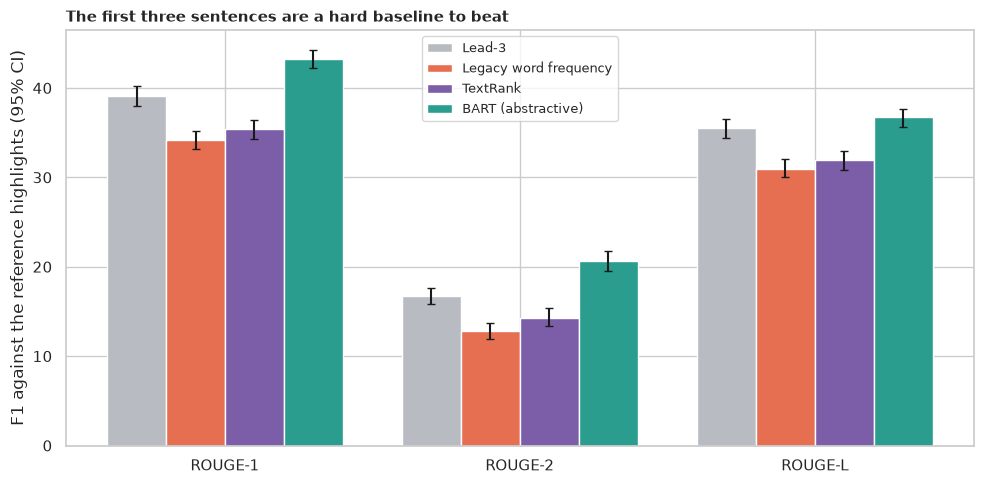

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
colors = {
    "Lead-3": GREY,
    "Legacy word frequency": ORANGE,
    "TextRank": PURPLE,
    "BART (abstractive)": TEAL,
}
for k, (name, color) in enumerate(colors.items()):
    vals = [board.loc[name, m] for m in ("R1", "R2", "RL")]
    lows = [board.loc[name, m] - board.loc[name, m + " low"] for m in ("R1", "R2", "RL")]
    highs = [board.loc[name, m + " high"] - board.loc[name, m] for m in ("R1", "R2", "RL")]
    ax.bar(x + (k - 1.5) * 0.2, vals, 0.2, color=color, label=name, yerr=[lows, highs], capsize=3)
ax.set_xticks(x, ["ROUGE-1", "ROUGE-2", "ROUGE-L"])
ax.set_ylabel("F1 against the reference highlights (95% CI)")
ax.set_title(
    "The first three sentences are a hard baseline to beat",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_rouge_by_system.png", dpi=150)
plt.show()

**How to read this:**

| System | Words | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---|---|---|
| Lead-3 | 75.5 | **39.1** | **16.7** | **35.5** |
| Legacy word frequency | 68.8 | 34.2 | 12.8 | 30.9 |
| TextRank | 75.5 | 35.4 | 14.3 | 31.9 |
| BART (abstractive) | 63.4 | **43.3** | **20.6** | **36.7** |

- **The legacy method is clearly worse than the first three sentences:** the mean difference is **-4.9** ROUGE-1 points (95% CI -6.0 to -3.9), **-3.9** ROUGE-2 and **-4.6** ROUGE-L, with Wilcoxon p-values of about 1e-15 to 1e-16. **We reject H₀.**
- **Why?** Word counts favour long sentences full of common words, wherever they are, while the point of a news story is at the top. The legacy method also skips sentences of 30 words or more, which in news can be exactly the important ones.
- **Time:** BART took about **2.3 seconds per article** on this 8 GB GPU (a batch of 4, with some memory pressure, so this is a pessimistic figure), while the extractive methods take milliseconds.

## 7. H2: does a graph method help?

*What:* compare TextRank with lead-3 and with the legacy method on the same articles, with the same tests. *Why:* TextRank is the best-known "smarter" extractive method; the question is whether centrality beats position.

In [6]:
paired("TextRank", "Lead-3", "TextRank minus lead-3")
paired("TextRank", "Legacy word frequency", "TextRank minus legacy frequency")

TextRank minus lead-3: R1 -3.7 (95% CI -4.8 to -2.7, p = 1.4e-10); R2 -2.4 (95% CI -3.3 to -1.5, p = 2.9e-07); RL -3.6 (95% CI -4.6 to -2.6, p = 7.7e-11)
TextRank minus legacy frequency: R1 +1.2 (95% CI +0.4 to +2.2, p = 1.7e-03); R2 +1.5 (95% CI +0.7 to +2.3, p = 1.6e-05); RL +1.0 (95% CI +0.1 to +1.9, p = 5.0e-03)


**How to read this:**

- **TextRank is better than the legacy word-count method:** **+1.2** ROUGE-1 points (95% CI +0.4 to +2.2, p = 0.002), **+1.5** ROUGE-2 and **+1.0** ROUGE-L. A small but consistent gain.
- **But TextRank is still worse than lead-3:** **-3.7** ROUGE-1 (CI -4.8 to -2.7), **-2.4** ROUGE-2 and **-3.6** ROUGE-L, all with p below 1e-6. **We reject H₀.**
- **The lesson:** being "central" in the article is not the same as being important in a news story. The first three sentences are a baseline that every smarter extractive method has to earn its way past.

## 8. H3: how much does an abstractive model add, and how much is left?

*What:* compare BART with lead-3 and with TextRank article by article, and compute a **greedy oracle**: for each article, the three sentences chosen *with the reference in view* so that their ROUGE is as high as possible (the best any three-sentence extractive summary could do, up to the greedy approximation). *Why:* the oracle tells us how much of the gap between lead-3 and a perfect extractive method is left to close.

In [7]:
def greedy_oracle(
    sentences: list[str], reference: str, n: int = N_SENTENCES, cap: int = 40
) -> list[int]:
    """The best n sentences an extractive method could choose, picked greedily with the answer.

    Args:
        sentences: The article's sentences.
        reference: The reference summary.
        n: Number of sentences.
        cap: Only the first ``cap`` sentences are considered (to keep this fast).

    Returns:
        The chosen sentence positions, in article order.
    """
    chosen: list[int] = []
    best = 0.0
    for _ in range(n):
        candidates = []
        for i in range(min(len(sentences), cap)):
            if i in chosen:
                continue
            trial = "\n".join(sentences[j] for j in sorted(chosen + [i]))
            s = scorer.score(reference, trial)
            candidates.append(((s["rouge1"].fmeasure + s["rouge2"].fmeasure) / 2, i))
        if not candidates:
            break
        score, i = max(candidates)
        if score <= best:
            break
        best = score
        chosen.append(i)
    return sorted(chosen)


oracle_positions = [
    greedy_oracle(s, h) for s, h in zip(sample["sentences"], sample["highlights"], strict=True)
]
summaries["Oracle (best 3 sentences)"] = [
    [s[i] for i in pos] for s, pos in zip(sample["sentences"], oracle_positions, strict=True)
]
scores["Oracle (best 3 sentences)"] = rouge_table(summaries["Oracle (best 3 sentences)"])
for metric in ("R1", "R2", "RL"):
    print(
        f"{metric}: lead-3 {scores['Lead-3'][metric].mean():.1f}, BART "
        f"{scores['BART (abstractive)'][metric].mean():.1f}, oracle "
        f"{scores['Oracle (best 3 sentences)'][metric].mean():.1f}"
    )
paired("BART (abstractive)", "Lead-3", "BART minus lead-3")
paired("BART (abstractive)", "TextRank", "BART minus TextRank")
wins = {
    m: float((scores["BART (abstractive)"][m] > scores["Lead-3"][m]).mean())
    for m in ("R1", "R2", "RL")
}
print(
    "Share of articles where BART beats lead-3: "
    + ", ".join(f"{m} {v:.0%}" for m, v in wins.items())
)

R1: lead-3 39.1, BART 43.3, oracle 55.7
R2: lead-3 16.7, BART 20.6, oracle 32.1
RL: lead-3 35.5, BART 36.7, oracle 51.6
BART minus lead-3: R1 +4.1 (95% CI +3.2 to +5.0, p = 9.0e-17); R2 +3.9 (95% CI +3.0 to +4.8, p = 1.2e-16); RL +1.2 (95% CI +0.3 to +2.1, p = 2.4e-02)
BART minus TextRank: R1 +7.8 (95% CI +6.7 to +8.9, p = 1.4e-35); R2 +6.4 (95% CI +5.4 to +7.5, p = 2.8e-28); RL +4.8 (95% CI +3.8 to +5.9, p = 4.8e-15)
Share of articles where BART beats lead-3: R1 66%, R2 65%, RL 53%


**How to read this:**

- **BART beats the first three sentences:** **+4.1** ROUGE-1 points (95% CI +3.2 to +5.0), **+3.9** ROUGE-2 (+3.0 to +4.8) and **+1.2** ROUGE-L (+0.3 to +2.1, p = 0.024). It scores higher in **66%, 65% and 53%** of the articles (ROUGE-1, -2, -L). The gain in ROUGE-L, which rewards long common sequences, is small. **We reject H₀.**
- **BART beats TextRank by a wide margin:** **+7.8** ROUGE-1, **+6.4** ROUGE-2 and **+4.8** ROUGE-L (all p below 1e-14).
- **There is a lot of room above lead-3 for extractive methods:** the oracle reaches ROUGE-1 **55.7**, ROUGE-2 **32.1** and ROUGE-L **51.6**, against lead-3's 39.1, 16.7 and 35.5. BART closes about a quarter of the ROUGE-1 gap to the oracle (4.1 of 16.6 points), but the oracle sees the reference, so it is an upper bound, not a target.
- **Remember what ROUGE measures:** BART's summaries are shorter (63 words against 75) and fluent, but a higher ROUGE is not proof of a better or more faithful summary.

## 9. H4: where do the best sentences live?

*What:* the position (0 = first sentence) of each sentence the oracle chooses, and the Spearman correlation between an article's length in sentences and the ROUGE-1 of its first three sentences. *Why:* it explains why lead-3 is so hard to beat, and where it fails.

Sentences the oracle picks: 1300 in 500 articles
  from the first 3 sentences: 31%; first 10: 69%; later than the 10th: 31%
Spearman correlation between article length (sentences) and lead-3 ROUGE-1: -0.26, p = 5.1e-09
Oracle minus lead-3 ROUGE-1: +16.5 points; articles where lead-3 already equals the oracle: 1%


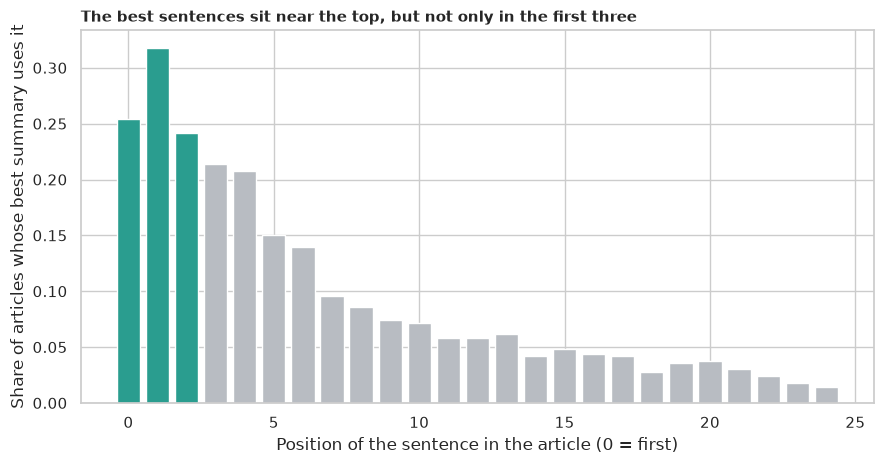

In [8]:
positions = np.array([p for pos in oracle_positions for p in pos])
first3 = (positions < 3).mean()
print(f"Sentences the oracle picks: {len(positions)} in {len(sample)} articles")
print(
    f"  from the first 3 sentences: {first3:.0%}; first 10: {(positions < 10).mean():.0%}; "
    f"later than the 10th: {(positions >= 10).mean():.0%}"
)
rho = stats.spearmanr(sample["n_sentences"], scores["Lead-3"]["R1"])
print(
    f"Spearman correlation between article length (sentences) and lead-3 ROUGE-1: "
    f"{rho.statistic:+.2f}, p = {fmt_p(rho.pvalue)}"
)
gap = scores["Oracle (best 3 sentences)"]["R1"] - scores["Lead-3"]["R1"]
print(
    f"Oracle minus lead-3 ROUGE-1: {gap.mean():+.1f} points; articles where lead-3 already "
    f"equals the oracle: {(gap.abs() < 0.01).mean():.0%}"
)
fig, ax = plt.subplots(figsize=(9, 4.8))
counts = pd.Series(positions).value_counts().reindex(range(25), fill_value=0)
ax.bar(
    counts.index, counts.values / len(sample), color=[TEAL if i < 3 else GREY for i in counts.index]
)
ax.set_xlabel("Position of the sentence in the article (0 = first)")
ax.set_ylabel("Share of articles whose best summary uses it")
ax.set_title(
    "The best sentences sit near the top, but not only in the first three",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_oracle_positions.png", dpi=150)
plt.show()

**How to read this:**

- **The oracle's sentences come from near the top, but not only from the top:** of **1,300** sentences chosen across 500 articles, **31%** are among the first three, **69%** among the first ten and **31%** come after the tenth. Lead-3 captures the first group and misses the rest.
- **Longer articles hurt lead-3:** the Spearman correlation between the article's length in sentences and lead-3's ROUGE-1 is **-0.26** (p = 5e-9): in a longer story the key facts are less often all in the opening.
- **Lead-3 has a lot of room above it:** the oracle's ROUGE-1 is **16.5 points** higher on average, and lead-3 already equals the oracle in only **1%** of the articles. **We reject H₀:** the positions are concentrated near the top, but not exclusively.

## 10. H5: does the abstractive model invent things?

*What:* for each system, the share of the summary's single words and word pairs that never occur in the article ("novel"), and a crude check for **made-up facts**: numbers and capitalised words (names) in the summary that appear nowhere in the article in any capitalisation. We print the two summaries with the most such items. *Why:* an abstractive model writes its own sentences, and the risk is that it adds a fact the article does not support. This check is deliberately simple and will miss subtle errors (a wrong number that appears elsewhere in the article, a swapped name).

In [9]:
def tokens(text: str) -> list[str]:
    """Lower-cased word tokens."""
    return re.findall(r"[a-z0-9']+", text.lower())


def novel_share(summary: str, article: str, n: int) -> float:
    """Share of the summary's n-grams that never occur in the article."""
    s, a = tokens(summary), tokens(article)

    def grams(t: list[str]) -> set[tuple[str, ...]]:
        return {tuple(t[i : i + n]) for i in range(len(t) - n + 1)}

    mine = grams(s)
    return len(mine - grams(a)) / max(len(mine), 1)


def unsupported_facts(summary: str, article: str) -> list[str]:
    """Numbers and capitalised words in the summary whose text appears nowhere in the article.

    A capitalised word counts only if it is missing from the article in any capitalisation, so
    an ordinary word that starts a sentence ("They", "But") is not flagged.

    Args:
        summary: The summary.
        article: The article it summarises.

    Returns:
        The unsupported numbers and capitalised words.
    """
    lowered = article.lower()
    facts = set(re.findall(r"\b\d[\d,.]*\b|\b[A-Z][a-z]{2,}\b", summary))
    return sorted(f for f in facts if f.lower() not in lowered)


rows = []
for name in ("Lead-3", "TextRank", "BART (abstractive)"):
    texts = [" ".join(c) for c in summaries[name]]
    unigram = [novel_share(t, a, 1) for t, a in zip(texts, sample["article"], strict=True)]
    bigram = [novel_share(t, a, 2) for t, a in zip(texts, sample["article"], strict=True)]
    facts = np.array(
        [len(unsupported_facts(t, a)) for t, a in zip(texts, sample["article"], strict=True)]
    )
    rows.append(
        {
            "system": name,
            "novel words": np.mean(unigram),
            "novel word pairs": np.mean(bigram),
            "summaries with an unsupported number or name": (facts > 0).mean(),
        }
    )
novelty = pd.DataFrame(rows).set_index("system")
print(novelty.round(3).to_string())
bart_facts = np.array(
    [
        len(unsupported_facts(c[0], a))
        for c, a in zip(summaries["BART (abstractive)"], sample["article"], strict=True)
    ]
)
print(
    f"\nBART summaries with at least one unsupported item: {(bart_facts > 0).mean():.1%}; "
    f"unsupported items per summary: mean {bart_facts.mean():.2f}, worst {bart_facts.max()}"
)
for i in np.argsort(-bart_facts)[:2]:
    missing = unsupported_facts(summaries["BART (abstractive)"][i][0], sample["article"].iloc[i])
    print(f"\nArticle {i}: summary items not found in the article: {missing}")
    print("  " + summaries["BART (abstractive)"][i][0][:300])

                    novel words  novel word pairs  summaries with an unsupported number or name
system                                                                                         
Lead-3                    0.000             0.000                                         0.000
TextRank                  0.000             0.028                                         0.000
BART (abstractive)        0.014             0.116                                         0.038

BART summaries with at least one unsupported item: 3.8%; unsupported items per summary: mean 0.07, worst 4

Article 90: summary items not found in the article: ['Etihad', 'Park', 'Selhurst', 'Stadium']
  Premier League and FA Cup semi-finals take place this weekend. Crystal Palace host West Bromwich Albion at Selhurst Park on Saturday. Manchester City host West Ham United at the Etihad Stadium on Sunday. Aston Villa face Liverpool in the FA Cup final at Villa Park on Sunday afternoon.

Article 324: summary items n

**How to read this:**

- **BART's wording is mostly copied:** only **1.4%** of its words and **11.6%** of its word pairs are novel (the other methods copy whole sentences, so their novel word pairs come only from the places where two sentences are joined).
- **A few summaries contain things the article does not:** **3.8%** of BART's summaries contain at least one number or name absent from the article (0% for the extractive methods, by construction), with an average of **0.07** such items per summary and at most 4 in one summary.
- **The examples show the typical cause:** in one summary BART writes "Selhurst Park" and "Etihad Stadium", names that the article does not contain: details BART learnt in pretraining, plausible but unchecked. In another, a person's name is respelled.
- **We reject H₀ for BART:** it does sometimes add content; the rate is low by this crude measure, and a real faithfulness check needs a human or a dedicated model.

## 11. 🎯 Takeaways

1. **The legacy word-count method loses to the first three sentences:** ROUGE-1 34.2 against 39.1 (-4.9, CI -6.0 to -3.9); news is written with the point first.
2. **A graph method helps a little and not enough:** TextRank beats the legacy method by 1.2 ROUGE-1 points but loses to lead-3 by 3.7.
3. **An abstractive model beats the lead baseline:** BART gets ROUGE-1 43.3 against 39.1 (+4.1) and ROUGE-2 20.6 against 16.7 (+3.9), but ROUGE-L only +1.2, and it wins in two-thirds, not all, of the articles.
4. **There is much room left:** an oracle picking the best three sentences reaches ROUGE-1 55.7; 31% of its sentences lie beyond the 10th.
5. **Abstractive does not mean faithful:** about 4% of BART's summaries contain a number or name that the article does not.
6. **Always compare with the simplest baseline, and with the reference,** before believing that a clever method works.

## 12. ⚠️ Limitations

- **News only, and one dataset.** CNN/DailyMail articles have a strong lead bias; for scientific papers, meeting notes or Wikipedia pages (the legacy input) lead-3 would not be the hard baseline it is here.
- **500 articles** from the test set; the intervals describe this sample.
- **ROUGE is a word-overlap measure.** It cannot tell a faithful paraphrase from a wrong sentence with the right words, and it rewards copying the reference's wording.
- **The reference is one journalist's bullet points.** Other good summaries exist and would score lower.
- **BART was fine-tuned on this dataset's training set,** so it is at home here; the extractive methods were not tuned at all (sentence count, the 30-word cut-off of the legacy method).
- **The oracle is greedy and uses the reference,** so it is an optimistic bound, restricted to the first 40 sentences.
- **The faithfulness check is crude:** it only finds numbers and capitalised words that are missing from the article; it misses errors that are subtle or that reuse words from elsewhere in the article.
- **Long articles are cut** at 1,024 word-pieces for BART, which can lose information at the end.
- **The BART timing is rough:** it was measured on a small GPU that ran short of memory during generation (a one-line memory-allocator warning from that run was removed from the output).
- **No human evaluation.**